In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!mkdir -p /content/dataset
!unzip -q "/content/drive/MyDrive/brain_tumor/dataset.zip" -d /content/dataset
!ls /content/dataset

data.yaml  test  train	valid


In [ ]:
import os
for s in ["train", "valid", "test"]:
    print(s, "images:", len(os.listdir(f"/content/dataset/{s}/images")),
             "labels:", len(os.listdir(f"/content/dataset/{s}/labels")))

train images: 2444 labels: 2444
valid images: 1074 labels: 1074
test images: 385 labels: 385


In [ ]:
!nvidia-smi

Fri Nov 20 08:50:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -q ultralytics

In [ ]:
import yaml
with open("/content/dataset/data.yaml") as f:
    d = yaml.safe_load(f)

cfg = {
    "path": "/content/dataset",
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": d["names"],
}
with open("/content/dataset/data_fixed.yaml", "w") as f:
    yaml.dump(cfg, f)

print(d["names"])

['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


In [ ]:
import time, os, pandas as pd
from ultralytics import YOLO

DATA = "/content/dataset/data_fixed.yaml"
OUT = "/content/drive/MyDrive/brain_tumor/runs"
CSV = "/content/drive/MyDrive/brain_tumor/results.csv"

models = {
    "YOLOv8": "yolov8n.pt",
    "YOLOv9": "yolov9t.pt",
    "YOLOv10": "yolov10n.pt",
    "YOLOv11": "yolo11n.pt",
    "YOLO26": "yolo26n.pt",
}

rows = pd.read_csv(CSV).to_dict("records") if os.path.exists(CSV) else []
done = {(r["Model"], r["Epoch"]) for r in rows}

for name, weight in models.items():
    for ep in [15, 30]:
        if (name, ep) in done:
            continue
        run = f"{name}_ep{ep}"
        t0 = time.time()
        m = YOLO(weight)
        _ = m.train(data=DATA, epochs=ep, imgsz=640, batch=16, seed=0,
                    project=OUT, name=run, exist_ok=True)
        mins = round((time.time() - t0) / 60, 1)

        bm = YOLO(f"{OUT}/{run}/weights/best.pt")
        params = sum(p.numel() for p in bm.model.parameters())
        r = bm.val(data=DATA, split="test", imgsz=640)
        P, R = r.box.mp, r.box.mr
        rows.append({
            "Model": name, "Epoch": ep, "Classes": 4,
            "Params": params, "Precision": round(P, 4), "Recall": round(R, 4),
            "F1": round(2*P*R/(P+R), 4),
            "mAP50": round(r.box.map50, 4), "mAP50-95": round(r.box.map, 4),
            "TrainMin": mins, "Inference_ms": round(r.speed["inference"], 2),
        })
        pd.DataFrame(rows).to_csv(CSV, index=False)
        print("Done:", run)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data_fixed.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv8_ep15, nbs=64, nms=None, opset=None, optimize=False

In [ ]:
import pandas as pd
pd.read_csv("/content/drive/MyDrive/brain_tumor/results.csv")


,Model,Epoch,Classes,Params,Precision,Recall,F1,mAP50,mAP50-95,TrainMin,Inference_ms
0,YOLOv8,15,4,3138732,0.9280,0.9098,0.9188,0.9522,0.7556,10.3,4.89
1,YOLOv8,30,4,3138732,0.9478,0.9011,0.9239,0.9617,0.7642,20.8,4.67
2,YOLOv9,15,4,2110252,0.9311,0.9081,0.9194,0.9549,0.7558,13.4,6.15
3,YOLOv9,30,4,2110252,0.9203,0.9171,0.9187,0.9499,0.7589,26.9,7.00
4,YOLOv10,15,4,2738584,0.9517,0.8901,0.9199,0.9542,0.7488,12.3,4.48
5,YOLOv10,30,4,2738584,0.9419,0.9129,0.9272,0.9573,0.7652,24.2,4.41
6,YOLOv11,15,4,2605612,0.9364,0.8888,0.9120,0.9471,0.7505,11.3,4.26
7,YOLOv11,30,4,2605612,0.9346,0.8855,0.9094,0.9465,0.7618,22.6,4.06
8,YOLO26,15,4,2535344,0.9328,0.9062,0.9193,0.9609,0.7608,12.5,4.28
9,YOLO26,30,4,2535344,0.9434,0.8978,0.9200,0.9600,0.7675,25.1,5.04


In [ ]:
!pip install -q ultralytics

In [ ]:
from ultralytics.nn.tasks import DetectionModel
for y in ["yolov8n", "yolov9t", "yolov10n", "yolo11n", "yolo26n"]:
    m = DetectionModel(f"{y}.yaml", nc=4, verbose=False)
    print(y, sum(p.numel() for p in m.parameters()))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Overriding model.yaml nc=80 with nc=4
yolov8n 3011628
Overriding model.yaml nc=80 with nc=4
yolov9t 2006188
Overriding model.yaml nc=80 with nc=4
yolov10n 2708600
Overriding model.yaml nc=80 with nc=4
yolo11n 2590620
Overriding model.yaml nc=80 with nc=4
yolo26n 2505360


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/brain_tumor/results.csv")

params = {
    "YOLOv8": 3011628,
    "YOLOv9": 2006188,
    "YOLOv10": 2708600,
    "YOLOv11": 2590620,
    "YOLO26": 2505360,
}

df["Params"] = df["Model"].map(params)
df["Params_M"] = (df["Params"] / 1e6).round(2)
df["mAP50_per_M"] = (df["mAP50"] / (df["Params"] / 1e6)).round(3)

df.to_csv("/content/drive/MyDrive/brain_tumor/results_final.csv", index=False)
df

Mounted at /content/drive


,Model,Epoch,Classes,Params,Precision,Recall,F1,mAP50,mAP50-95,TrainMin,Inference_ms,Params_M,mAP50_per_M
0,YOLOv8,15,4,3011628,0.9280,0.9098,0.9188,0.9522,0.7556,10.3,4.89,3.01,0.316
1,YOLOv8,30,4,3011628,0.9478,0.9011,0.9239,0.9617,0.7642,20.8,4.67,3.01,0.319
2,YOLOv9,15,4,2006188,0.9311,0.9081,0.9194,0.9549,0.7558,13.4,6.15,2.01,0.476
3,YOLOv9,30,4,2006188,0.9203,0.9171,0.9187,0.9499,0.7589,26.9,7.00,2.01,0.473
4,YOLOv10,15,4,2708600,0.9517,0.8901,0.9199,0.9542,0.7488,12.3,4.48,2.71,0.352
5,YOLOv10,30,4,2708600,0.9419,0.9129,0.9272,0.9573,0.7652,24.2,4.41,2.71,0.353
6,YOLOv11,15,4,2590620,0.9364,0.8888,0.9120,0.9471,0.7505,11.3,4.26,2.59,0.366
7,YOLOv11,30,4,2590620,0.9346,0.8855,0.9094,0.9465,0.7618,22.6,4.06,2.59,0.365
8,YOLO26,15,4,2505360,0.9328,0.9062,0.9193,0.9609,0.7608,12.5,4.28,2.51,0.384
9,YOLO26,30,4,2505360,0.9434,0.8978,0.9200,0.9600,0.7675,25.1,5.04,2.51,0.383


In [ ]:
!git clone -q https://github.com/WongKinYiu/yolov7
%cd /content/yolov7
!wget -q https://github.com/WongKinYiu/yolov7/releases/download/v0.1/yolov7-tiny.pt
!ls

/content/yolov7
cfg	   export.py   LICENSE.md  requirements.txt  train_aux.py
data	   figure      models	   scripts	     train.py
deploy	   hubconf.py  paper	   test.py	     utils
detect.py  inference   README.md   tools	     yolov7-tiny.pt


In [ ]:
yaml_text = """
train: /content/dataset/train/images
val: /content/dataset/valid/images
test: /content/dataset/test/images
nc: 4
names: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
"""
open("/content/yolov7/data/brain.yaml", "w").write(yaml_text)
print(open("/content/yolov7/data/brain.yaml").read())


train: /content/dataset/train/images
val: /content/dataset/valid/images
test: /content/dataset/test/images
nc: 4
names: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']



In [ ]:
%cd /content/yolov7
%env TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1
!python train.py --weights yolov7-tiny.pt --cfg cfg/training/yolov7-tiny.yaml \
  --data data/brain.yaml --hyp data/hyp.scratch.tiny.yaml \
  --epochs 1 --batch-size 16 --img 640 640 --workers 2 --device 0 --name v7_smoke

/content/yolov7
env: TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1
I0000 00:00:1795187707.687448    9974 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
YOLOR 🚀 v0.1-128-ga207844 torch 2.14.1+cu130 CUDA:0 (Tesla T4, 14912.6875MB)

Namespace(weights='yolov7-tiny.pt', cfg='cfg/training/yolov7-tiny.yaml', data='data/brain.yaml', hyp='data/hyp.scratch.tiny.yaml', epochs=1, batch_size=16, img_size=[640, 640], rect=False, resume=False, nosave=False, notest=False, noautoanchor=False, evolve=False, bucket='', cache_images=False, image_weights=False, device='0', multi_scale=False, single_cls=False, adam=False, sync_bn=False, local_rank=-1, workers=2, project='runs/train', entity=None, name='v7_smoke', exist_ok=False, quad=False, linear_lr=False, label_smoothing=0.0, upload_dataset=False, bbox_interval=-1, save_period=-1, artifact_alias='latest', freeze=[0], v5_metric=False, world_size=1, global_rank=-1, save_dir='runs/train/v7_smoke', total_batch_size=16)
tensorboard:

In [ ]:
%cd /content
!rm -rf /content/yolov7
!git clone https://github.com/WongKinYiu/yolov7.git
%cd /content/yolov7
!wget -q https://github.com/WongKinYiu/yolov7/releases/download/v0.1/yolov7-tiny.pt -O yolov7-tiny.pt
!ls -lh yolov7-tiny.pt
!sed -i 's/np\.trapz/np.trapezoid/g' utils/metrics.py
!grep -n "trapezoid" utils/metrics.py

/content
Cloning into 'yolov7'...
remote: Enumerating objects: 1197, done.
remote: Total 1197 (delta 0), reused 0 (delta 0), pack-reused 1197 (from 1)
Receiving objects: 100% (1197/1197), 74.29 MiB | 19.86 MiB/s, done.
Resolving deltas: 100% (511/511), done.
/content/yolov7
-rw-r--r-- 1 root root 13M Jul  7  2022 yolov7-tiny.pt
105:        ap = np.trapezoid(np.interp(x, mrec, mpre), x)  # integrate


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/dataset
!unzip -n -q "/content/drive/MyDrive/brain_tumor/dataset.zip" -d /content/dataset
!ls /content/dataset

Mounted at /content/drive
data.yaml  test  train	valid


In [2]:
yaml_text = """
train: /content/dataset/train/images
val: /content/dataset/valid/images
test: /content/dataset/test/images
nc: 4
names: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
"""
open("/content/yolov7/data/brain.yaml", "w").write(yaml_text)
print(open("/content/yolov7/data/brain.yaml").read())

FileNotFoundError: [Errno 2] No such file or directory: '/content/yolov7/data/brain.yaml'

In [3]:
%cd /content
!test -d yolov7 || git clone -q https://github.com/WongKinYiu/yolov7
%cd /content/yolov7
!test -f yolov7-tiny.pt || wget -q https://github.com/WongKinYiu/yolov7/releases/download/v0.1/yolov7-tiny.pt
!ls

/content
/content/yolov7
cfg	   export.py   LICENSE.md  requirements.txt  train_aux.py
data	   figure      models	   scripts	     train.py
deploy	   hubconf.py  paper	   test.py	     utils
detect.py  inference   README.md   tools	     yolov7-tiny.pt


In [4]:
yaml_text = """
train: /content/dataset/train/images
val: /content/dataset/valid/images
test: /content/dataset/test/images
nc: 4
names: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
"""
open("/content/yolov7/data/brain.yaml", "w").write(yaml_text)
print(open("/content/yolov7/data/brain.yaml").read())


train: /content/dataset/train/images
val: /content/dataset/valid/images
test: /content/dataset/test/images
nc: 4
names: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']



In [6]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/dataset
!unzip -n -q "/content/drive/MyDrive/brain_tumor/dataset.zip" -d /content/dataset
!ls /content/dataset
!ls /content/dataset/valid/images | head -3

Mounted at /content/drive
data.yaml  test  train	valid
5_jpg.rf.d71982210195f5c9861d89ae98da05f8.jpg
gg-117-_jpg.rf.6014b62d2cc7c3f1b77ab8b9190e82a6.jpg
gg-118-_jpg.rf.5ca6ce08b3fc795f9722fb09113d3269.jpg


In [8]:
!sed -i 's/np.trapz/np.trapezoid/g' /content/yolov7/utils/metrics.py
!grep -n "trapezoid" /content/yolov7/utils/metrics.py

105:        ap = np.trapezoid(np.interp(x, mrec, mpre), x)  # integrate


In [9]:
%cd /content/yolov7
%env TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1
%env WANDB_MODE=disabled
!python train.py --weights yolov7-tiny.pt --cfg cfg/training/yolov7-tiny.yaml \
  --data data/brain.yaml --hyp data/hyp.scratch.tiny.yaml \
  --epochs 1 --batch-size 16 --img 640 640 --workers 2 --device 0 \
  --name v7_smoke --exist-ok

/content/yolov7
env: TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1
env: WANDB_MODE=disabled
I0000 00:00:1795253449.848917    4056 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795253452.310593    4056 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
YOLOR 🚀 v0.1-128-ga207844 torch 2.14.1+cu130 CUDA:0 (Tesla T4, 14912.6875MB)

Namespace(weights='yolov7-tiny.pt', cfg='cfg/training/yolov7-tiny.yaml', data='data/brain.yaml', hyp='data/hyp.scratch.tiny.yaml', epochs=1, batch_size=16, img_size=[640, 640], rect=False, resume=False, nosave=False, notest=False, noautoanchor=False, evolve=False, bucket='', cache_images=False, image_weights=False, device='0', multi_scale=False, single_cls=False, adam=False, sync_bn=False, local_rank=-1, worker

In [10]:
import os, re, time, shutil, subprocess
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/brain_tumor"
CSV = f"{BASE}/results_final.csv"
Y7 = "/content/yolov7"
env = {**os.environ, "TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD": "1", "WANDB_MODE": "disabled"}

# ---- setup (restart hole-o safe) ----
os.makedirs("/content/dataset", exist_ok=True)
if not os.path.exists("/content/dataset/train"):
    subprocess.run(["unzip", "-n", "-q", f"{BASE}/dataset.zip", "-d", "/content/dataset"], check=True)
if not os.path.exists(Y7):
    subprocess.run(["git", "clone", "-q", "https://github.com/WongKinYiu/yolov7", Y7], check=True)
if not os.path.exists(f"{Y7}/yolov7-tiny.pt"):
    subprocess.run(["wget", "-q", "-P", Y7, "https://github.com/WongKinYiu/yolov7/releases/download/v0.1/yolov7-tiny.pt"], check=True)
subprocess.run(["sed", "-i", "s/np.trapz/np.trapezoid/g", f"{Y7}/utils/metrics.py"], check=True)
open(f"{Y7}/data/brain.yaml", "w").write("""train: /content/dataset/train/images
val: /content/dataset/valid/images
test: /content/dataset/test/images
nc: 4
names: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
""")

def run(cmd, show=True):
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                         text=True, cwd=Y7, env=env)
    lines = []
    for line in p.stdout:
        lines.append(line)
        s = line.strip()
        if show and (s.startswith("all") or "epochs completed" in s):
            print(s)
    p.wait()
    if p.returncode != 0:
        print("".join(lines[-25:]))
        raise RuntimeError("Command failed, upore-r error dekho")
    return "".join(lines)

PARAMS = 6023106  # YOLOv7-tiny, training log-er parameters = gradients
df = pd.read_csv(CSV)

for ep in [15, 30]:
    if ((df["Model"] == "YOLOv7") & (df["Epoch"] == ep)).any():
        print("Skip (already done): YOLOv7", ep)
        continue
    t0 = time.time()
    run(["python", "train.py", "--weights", "yolov7-tiny.pt",
         "--cfg", "cfg/training/yolov7-tiny.yaml", "--data", "data/brain.yaml",
         "--hyp", "data/hyp.scratch.tiny.yaml", "--epochs", str(ep),
         "--batch-size", "16", "--img", "640", "640", "--workers", "2",
         "--device", "0", "--name", f"v7_ep{ep}", "--exist-ok"])
    mins = round((time.time() - t0) / 60, 1)

    out = run(["python", "test.py", "--data", "data/brain.yaml", "--img", "640",
               "--batch", "32", "--conf", "0.001", "--iou", "0.65", "--device", "0",
               "--weights", f"runs/train/v7_ep{ep}/weights/best.pt",
               "--task", "test", "--name", f"v7_ep{ep}_test", "--exist-ok"], show=False)
    m = re.search(r"^\s*all\s+(\d+)\s+(\d+)\s+([\d.eE+-]+)\s+([\d.eE+-]+)\s+([\d.eE+-]+)\s+([\d.eE+-]+)",
                  out, re.M)
    n_img, n_lab, P, R, m50, m5095 = int(m[1]), int(m[2]), *[float(m[i]) for i in range(3, 7)]
    sp = re.search(r"Speed: ([\d.]+)/", out)
    row = {"Model": "YOLOv7", "Epoch": ep, "Classes": 4, "Params": PARAMS,
           "Precision": round(P, 4), "Recall": round(R, 4),
           "F1": round(2 * P * R / (P + R), 4),
           "mAP50": round(m50, 4), "mAP50-95": round(m5095, 4),
           "TrainMin": mins, "Inference_ms": float(sp[1]) if sp else None,
           "Params_M": round(PARAMS / 1e6, 2),
           "mAP50_per_M": round(m50 / (PARAMS / 1e6), 3)}
    df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    df.to_csv(CSV, index=False)
    shutil.copytree(f"{Y7}/runs/train/v7_ep{ep}", f"{BASE}/runs/yolov7_ep{ep}", dirs_exist_ok=True)
    print("Done: YOLOv7", ep, "| test images:", n_img, "| P/R/mAP50:", P, R, m50)]3

df

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
all        1074        1224      0.0538       0.221      0.0321      0.0107
all        1074        1224       0.345       0.522       0.326       0.159
all        1074        1224       0.594       0.431       0.449        0.26
all        1074        1224       0.543       0.471       0.404       0.234
all        1074        1224       0.677       0.447       0.536       0.278
all        1074        1224       0.445       0.586       0.535       0.297
all        1074        1224       0.474       0.362       0.306       0.168
all        1074        1224       0.669       0.557       0.641       0.383
all        1074        1224        0.61       0.637       0.665       0.404
all        1074        1224       0.779       0.692       0.773       0.499
all        1074        1224       0.753       0.739       0.779       0.531
all        1074        1224       0

,Model,Epoch,Classes,Params,Precision,Recall,F1,mAP50,mAP50-95,TrainMin,Inference_ms,Params_M,mAP50_per_M
0,YOLOv8,15,4,3011628,0.9280,0.9098,0.9188,0.9522,0.7556,10.3,4.89,3.01,0.316
1,YOLOv8,30,4,3011628,0.9478,0.9011,0.9239,0.9617,0.7642,20.8,4.67,3.01,0.319
2,YOLOv9,15,4,2006188,0.9311,0.9081,0.9194,0.9549,0.7558,13.4,6.15,2.01,0.476
3,YOLOv9,30,4,2006188,0.9203,0.9171,0.9187,0.9499,0.7589,26.9,7.00,2.01,0.473
4,YOLOv10,15,4,2708600,0.9517,0.8901,0.9199,0.9542,0.7488,12.3,4.48,2.71,0.352
5,YOLOv10,30,4,2708600,0.9419,0.9129,0.9272,0.9573,0.7652,24.2,4.41,2.71,0.353
6,YOLOv11,15,4,2590620,0.9364,0.8888,0.9120,0.9471,0.7505,11.3,4.26,2.59,0.366
7,YOLOv11,30,4,2590620,0.9346,0.8855,0.9094,0.9465,0.7618,22.6,4.06,2.59,0.365
8,YOLO26,15,4,2505360,0.9328,0.9062,0.9193,0.9609,0.7608,12.5,4.28,2.51,0.384
9,YOLO26,30,4,2505360,0.9434,0.8978,0.9200,0.9600,0.7675,25.1,5.04,2.51,0.383


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


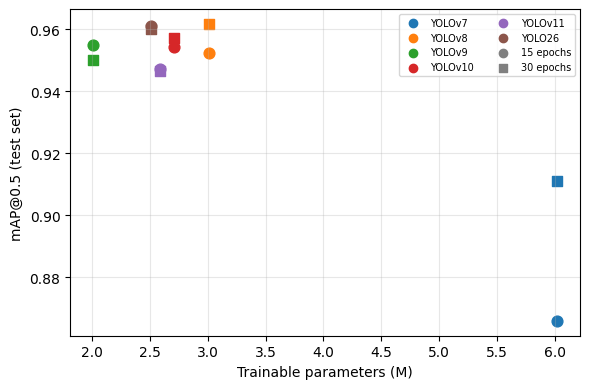

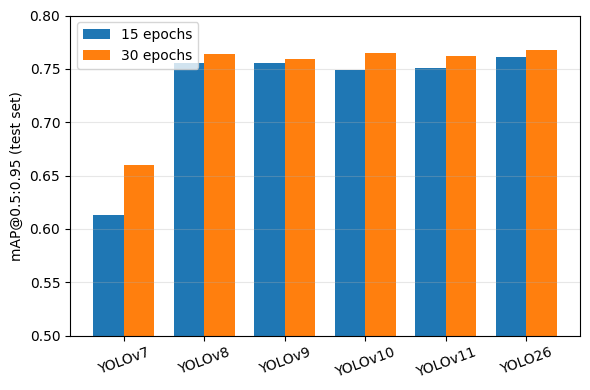

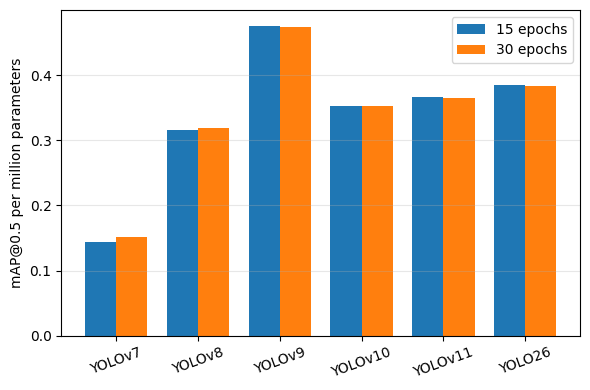

In [11]:
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/brain_tumor"
df = pd.read_csv(f"{BASE}/results_final.csv")
os.makedirs(f"{BASE}/figures", exist_ok=True)
order = ["YOLOv7", "YOLOv8", "YOLOv9", "YOLOv10", "YOLOv11", "YOLO26"]
colors = dict(zip(order, plt.cm.tab10.colors))

# Fig 1: parameter vs mAP@0.5
fig, ax = plt.subplots(figsize=(6, 4))
for _, r in df.iterrows():
    ax.scatter(r["Params_M"], r["mAP50"], color=colors[r["Model"]],
               marker="o" if r["Epoch"] == 15 else "s", s=60)
for m in order:
    ax.scatter([], [], color=colors[m], label=m)
ax.scatter([], [], color="gray", marker="o", label="15 epochs")
ax.scatter([], [], color="gray", marker="s", label="30 epochs")
ax.set_xlabel("Trainable parameters (M)")
ax.set_ylabel("mAP@0.5 (test set)")
ax.grid(alpha=0.3)
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(f"{BASE}/figures/fig1_params_vs_map50.png", dpi=300)

def grouped(col, ylabel, fname, ylim=None):
    p = df.pivot(index="Model", columns="Epoch", values=col).loc[order]
    x = np.arange(len(order)); w = 0.38
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(x - w/2, p[15], w, label="15 epochs")
    ax.bar(x + w/2, p[30], w, label="30 epochs")
    ax.set_xticks(x); ax.set_xticklabels(order, rotation=20)
    ax.set_ylabel(ylabel)
    if ylim: ax.set_ylim(*ylim)
    ax.legend(); ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(f"{BASE}/figures/{fname}", dpi=300)

# Fig 2: 15 vs 30 epoch, mAP@0.5:0.95
grouped("mAP50-95", "mAP@0.5:0.95 (test set)", "fig2_epochs_map5095.png", (0.5, 0.8))
# Fig 3: parameter efficiency
grouped("mAP50_per_M", "mAP@0.5 per million parameters", "fig3_efficiency.png")
plt.show()